In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
PROJECT_ROOT = Path.cwd().parent

PROCESSED_FILE = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "train_FD001_with_rul.csv"
)

df = pd.read_csv(PROCESSED_FILE)

print("Dataset shape:", df.shape)

Dataset shape: (20631, 28)


In [3]:
feature_columns = [
    "op_setting_1",
    "op_setting_2",
    "op_setting_3"
]

feature_columns += [
    f"sensor_{i}"
    for i in range(1, 22)
]

target_column = "RUL"

X = df[feature_columns]
y = df[target_column]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (20631, 24)
Target: (20631,)


In [5]:
train_engines = df["unit_id"].unique()

train_engine_ids = train_engines[:80]
validation_engine_ids = train_engines[80:]

train_data = df[
    df["unit_id"].isin(train_engine_ids)
]

validation_data = df[
    df["unit_id"].isin(validation_engine_ids)
]

print("Training engines:", len(train_engine_ids))
print("Validation engines:", len(validation_engine_ids))

print("Training rows:", len(train_data))
print("Validation rows:", len(validation_data))

Training engines: 80
Validation engines: 20
Training rows: 16138
Validation rows: 4493


In [6]:
X_train = train_data[feature_columns]
y_train = train_data[target_column]

X_val = validation_data[feature_columns]
y_val = validation_data[target_column]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)

X_train: (16138, 24)
X_val: (4493, 24)


In [7]:
model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [8]:
y_pred = model.predict(X_val)

print("Predictions generated:", len(y_pred))

Predictions generated: 4493


In [9]:
mae = mean_absolute_error(
    y_val,
    y_pred
)

print("MAE:", mae)

MAE: 36.465598906724914


In [10]:
rmse = np.sqrt(
    mean_squared_error(
        y_val,
        y_pred
    )
)

print("RMSE:", rmse)

RMSE: 51.208184328896266


In [11]:
print("=" * 40)
print("ForgeMind RUL Baseline")
print("=" * 40)

print(f"MAE  : {mae:.2f} cycles")
print(f"RMSE : {rmse:.2f} cycles")

ForgeMind RUL Baseline
MAE  : 36.47 cycles
RMSE : 51.21 cycles


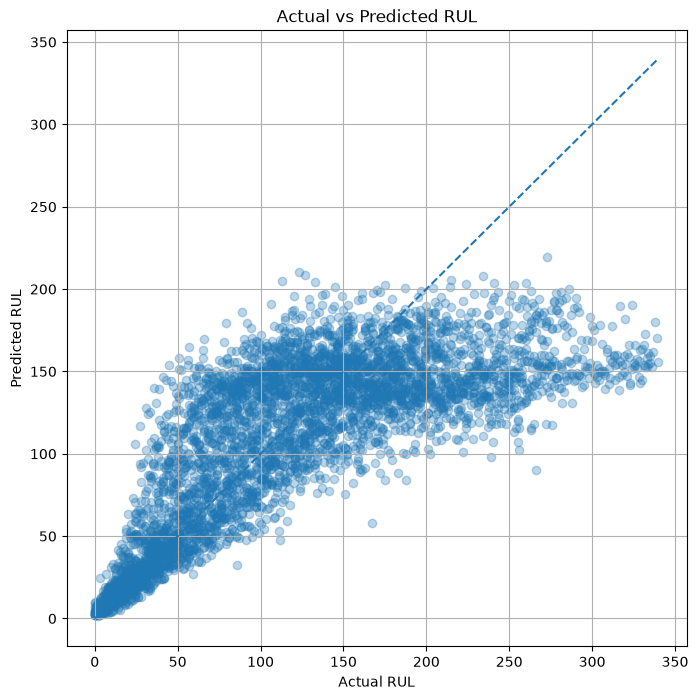

In [12]:
plt.figure(figsize=(8, 8))

plt.scatter(
    y_val,
    y_pred,
    alpha=0.3
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL")

plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    linestyle="--"
)

plt.grid(True)
plt.show()

In [13]:
importance = pd.Series(
    model.feature_importances_,
    index=feature_columns
).sort_values(ascending=False)

importance.head(10)

sensor_11    0.495751
sensor_9     0.131823
sensor_4     0.081828
sensor_12    0.043485
sensor_7     0.032259
sensor_14    0.031969
sensor_21    0.027475
sensor_15    0.026858
sensor_2     0.022297
sensor_3     0.021222
dtype: float64

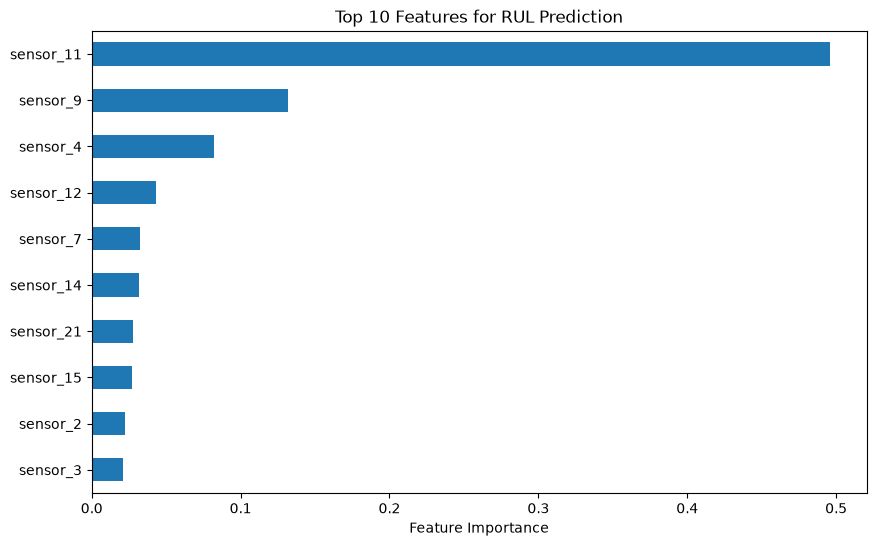

In [14]:
plt.figure(figsize=(10, 6))

importance.head(10).sort_values().plot(
    kind="barh"
)

plt.xlabel("Feature Importance")
plt.title("Top 10 Features for RUL Prediction")

plt.show()

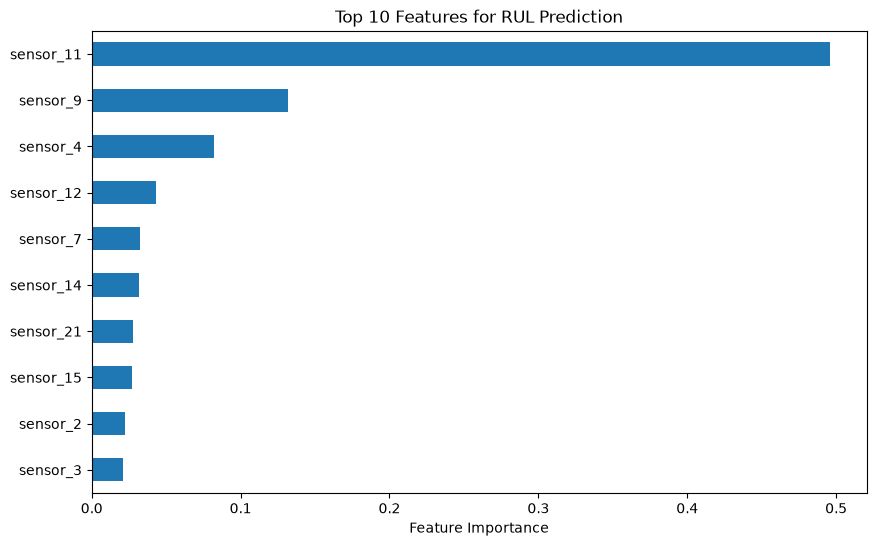

In [15]:
plt.figure(figsize=(10, 6))

importance.head(10).sort_values().plot(
    kind="barh"
)

plt.xlabel("Feature Importance")
plt.title("Top 10 Features for RUL Prediction")

plt.show()

In [17]:
results = validation_data[
    ["unit_id", "cycle", "RUL"]
].copy()

results["predicted_RUL"] = y_pred

results["error"] = (
    results["predicted_RUL"] - results["RUL"]
)

results["absolute_error"] = (
    results["error"].abs()
)

results.head()

,unit_id,cycle,RUL,predicted_RUL,error,absolute_error
16138,81,1,239,150.344020,-88.655980,88.655980
16139,81,2,238,128.496917,-109.503083,109.503083
16140,81,3,237,155.339574,-81.660426,81.660426
16141,81,4,236,149.605660,-86.394340,86.394340
16142,81,5,235,146.580953,-88.419047,88.419047


In [18]:
results = validation_data[
    ["unit_id", "cycle", "RUL"]
].copy()

results["predicted_RUL"] = y_pred

results["error"] = (
    results["predicted_RUL"] - results["RUL"]
)

results["absolute_error"] = (
    results["error"].abs()
)

results.head()

,unit_id,cycle,RUL,predicted_RUL,error,absolute_error
16138,81,1,239,150.344020,-88.655980,88.655980
16139,81,2,238,128.496917,-109.503083,109.503083
16140,81,3,237,155.339574,-81.660426,81.660426
16141,81,4,236,149.605660,-86.394340,86.394340
16142,81,5,235,146.580953,-88.419047,88.419047


In [19]:
results = validation_data[
    ["unit_id", "cycle", "RUL"]
].copy()

results["predicted_RUL"] = y_pred

results["error"] = (
    results["predicted_RUL"] - results["RUL"]
)

results["absolute_error"] = (
    results["error"].abs()
)

results.head()

,unit_id,cycle,RUL,predicted_RUL,error,absolute_error
16138,81,1,239,150.344020,-88.655980,88.655980
16139,81,2,238,128.496917,-109.503083,109.503083
16140,81,3,237,155.339574,-81.660426,81.660426
16141,81,4,236,149.605660,-86.394340,86.394340
16142,81,5,235,146.580953,-88.419047,88.419047


In [21]:
engine_errors = (
    results
    .groupby("unit_id")["absolute_error"]
    .mean()
    .sort_values(ascending=False)
)

engine_errors.head(10)

unit_id
92    65.426964
90    57.020862
96    55.058539
84    48.150906
86    44.367712
93    40.203087
94    38.988796
98    38.430463
83    37.871118
99    33.821313
Name: absolute_error, dtype: float64

In [22]:
worst_engine = engine_errors.index[0]

print("Worst engine:", worst_engine)

Worst engine: 92


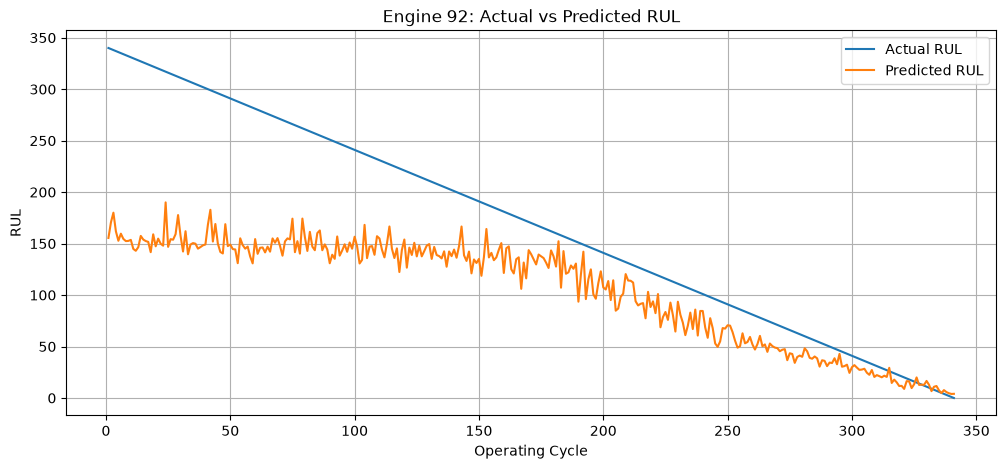

In [23]:
engine_result = results[
    results["unit_id"] == worst_engine
]

plt.figure(figsize=(12, 5))

plt.plot(
    engine_result["cycle"],
    engine_result["RUL"],
    label="Actual RUL"
)

plt.plot(
    engine_result["cycle"],
    engine_result["predicted_RUL"],
    label="Predicted RUL"
)

plt.xlabel("Operating Cycle")
plt.ylabel("RUL")
plt.title(
    f"Engine {worst_engine}: Actual vs Predicted RUL"
)

plt.legend()
plt.grid(True)

plt.show()

In [25]:
sensor_columns = [
    f"sensor_{i}"
    for i in range(1, 22)
]

print(sensor_columns)

['sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


In [26]:
sensor_variance = (
    train_data[sensor_columns]
    .var()
    .sort_values()
)

sensor_variance

sensor_1     0.000000e+00
sensor_10    0.000000e+00
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    1.926049e-34
sensor_5     1.262256e-29
sensor_6     2.009116e-06
sensor_15    1.407722e-03
sensor_8     5.127680e-03
sensor_13    5.271300e-03
sensor_21    1.179516e-02
sensor_20    3.277651e-02
sensor_11    7.151443e-02
sensor_2     2.507116e-01
sensor_12    5.450164e-01
sensor_7     7.884503e-01
sensor_17    2.399496e+00
sensor_3     3.757641e+01
sensor_4     8.058784e+01
sensor_14    3.893261e+02
sensor_9     5.189904e+02
dtype: float64

In [27]:
low_variance_sensors = sensor_variance[
    sensor_variance < 1e-5
].index.tolist()

print("Low variance sensors:")
print(low_variance_sensors)

Low variance sensors:
['sensor_1', 'sensor_10', 'sensor_19', 'sensor_18', 'sensor_16', 'sensor_5', 'sensor_6']


In [28]:
sensor_columns = [
    f"sensor_{i}"
    for i in range(1, 22)
]

sensor_variance = (
    train_data[sensor_columns]
    .var()
    .sort_values()
)

print("Sensor variance:")
print(sensor_variance)

Sensor variance:
sensor_1     0.000000e+00
sensor_10    0.000000e+00
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    1.926049e-34
sensor_5     1.262256e-29
sensor_6     2.009116e-06
sensor_15    1.407722e-03
sensor_8     5.127680e-03
sensor_13    5.271300e-03
sensor_21    1.179516e-02
sensor_20    3.277651e-02
sensor_11    7.151443e-02
sensor_2     2.507116e-01
sensor_12    5.450164e-01
sensor_7     7.884503e-01
sensor_17    2.399496e+00
sensor_3     3.757641e+01
sensor_4     8.058784e+01
sensor_14    3.893261e+02
sensor_9     5.189904e+02
dtype: float64


In [29]:
sensor_columns = [
    f"sensor_{i}"
    for i in range(1, 22)
]

sensor_variance = (
    train_data[sensor_columns]
    .var()
    .sort_values()
)

print("Sensor variance:")
print(sensor_variance)

Sensor variance:
sensor_1     0.000000e+00
sensor_10    0.000000e+00
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    1.926049e-34
sensor_5     1.262256e-29
sensor_6     2.009116e-06
sensor_15    1.407722e-03
sensor_8     5.127680e-03
sensor_13    5.271300e-03
sensor_21    1.179516e-02
sensor_20    3.277651e-02
sensor_11    7.151443e-02
sensor_2     2.507116e-01
sensor_12    5.450164e-01
sensor_7     7.884503e-01
sensor_17    2.399496e+00
sensor_3     3.757641e+01
sensor_4     8.058784e+01
sensor_14    3.893261e+02
sensor_9     5.189904e+02
dtype: float64


In [30]:
low_variance_sensors = sensor_variance[
    sensor_variance < 1e-5
].index.tolist()

print("Low variance sensors:")
print(low_variance_sensors)

Low variance sensors:
['sensor_1', 'sensor_10', 'sensor_19', 'sensor_18', 'sensor_16', 'sensor_5', 'sensor_6']


In [31]:
useful_sensors = [
    sensor
    for sensor in sensor_columns
    if sensor not in low_variance_sensors
]

clean_features = [
    "op_setting_1",
    "op_setting_2",
    "op_setting_3"
] + useful_sensors

print("Original sensor count:", len(sensor_columns))
print("Useful sensor count:", len(useful_sensors))
print("Total features:", len(clean_features))

Original sensor count: 21
Useful sensor count: 14
Total features: 17


In [32]:
X_train_clean = train_data[clean_features]
X_val_clean = validation_data[clean_features]

model_clean = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

model_clean.fit(
    X_train_clean,
    y_train
)

y_pred_clean = model_clean.predict(
    X_val_clean
)

In [33]:
mae_clean = mean_absolute_error(
    y_val,
    y_pred_clean
)

rmse_clean = np.sqrt(
    mean_squared_error(
        y_val,
        y_pred_clean
    )
)

print("=" * 50)
print("MODEL COMPARISON")
print("=" * 50)

print(f"Baseline MAE : {mae:.2f}")
print(f"Baseline RMSE: {rmse:.2f}")

print()

print(f"Clean MAE    : {mae_clean:.2f}")
print(f"Clean RMSE   : {rmse_clean:.2f}")

MODEL COMPARISON
Baseline MAE : 36.47
Baseline RMSE: 51.21

Clean MAE    : 36.44
Clean RMSE   : 51.19


In [34]:
experiment_results = pd.DataFrame({
    "model": [
        "Random Forest Baseline",
        "Random Forest Feature Engineered"
    ],
    "MAE": [
        mae,
        mae_clean
    ],
    "RMSE": [
        rmse,
        rmse_clean
    ]
})

experiment_results

,model,MAE,RMSE
0,Random Forest Baseline,36.465599,51.208184
1,Random Forest Feature Engineered,36.441915,51.185722
